# Training Notebook for the illness model

**This model attempts to classify the likelihood of a goat, sheep or cattle falling ill in the next 30 days as low, medium or high** 

Uses a logistic regression model and the results are displayed on the app's illness risk page.

## 1. Install dependencies and importing libraries

Libraries in 'requirements.txt' are already installed on docker

In [1]:
import os
import sys
import time
import warnings
from datetime import timedelta
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.calibration import calibration_curve
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.feature_selection import RFECV, mutual_info_classif
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, average_precision_score, confusion_matrix,
                             precision_recall_curve, roc_auc_score, roc_curve)
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit, cross_validate
from sklearn.naive_bayes import GaussianNB
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier

## 2. Setting up the environment
Notebook lives in the notebook/ folder and uses the Kwetu workbook for its dataset

In [2]:
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

WORKBOOK = Path(os.environ.get("KWETU_WORKBOOK", ROOT / "seeds" / "data" / "Kwetu_Animals_and_Records.xlsx"))
SEED = int(os.environ.get("SEED", 42))

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 140)
warnings.filterwarnings("ignore", category=FutureWarning)
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110})
OLIVE, TAN = "#5a6b3a", "#b08d57"

# The project's own code: the same steps the app uses.
from ml.dataset import FEATURES, days_since, features, labels
from ml.predict import HIGH_FROM, LOW_BELOW, risk_level
from ml.synthetic import simulate_farms
from ml.test import measure, weights
from ml.train import END, LABEL, MODEL_PATH, WARM_UP_DAYS, YEARS, load_bundle, save_bundle, split_by_time

print("Project folder:", ROOT)
print("Workbook:", WORKBOOK, "(found)" if WORKBOOK.exists() else "(NOT FOUND)")

Project folder: /app
Workbook: /app/seeds/data/Kwetu_Animals_and_Records.xlsx (found)


## 3. Loading the data

The data comes from Kwetu farm's real records, compiled into an Excel workbook.
Each sheet is read and then reshaped into the same tables as the app's database so that the same feature code works on them.

In [3]:
sheets = pd.read_excel(WORKBOOK, sheet_name=None)
pd.Series({name: len(df) for name, df in sheets.items()}, name="rows")

Read me              26
Animals             574
Births              150
Deaths              109
Sales & exits       126
Health records      117
Group treatments     26
Weights              20
Pharmacy            148
Head-count check     57
Notebook 2020-21     12
Problems found       26
Name: rows, dtype: int64

### Kwetu Farm Records from the Excel workbook

In [4]:
GROUP_SPECIES = {"Cattle": ["CATTLE"], "Goat": ["GOAT"], "Sheep": ["SHEEP"],
                 "Sheep, goats, calves": ["SHEEP", "GOAT", "CATTLE"], "Not stated": []}
GROUP_ACTIVITY = {"Tick spraying": "TICK_SPRAY", "Dipping": "TICK_SPRAY", "Deworming": "DEWORMING",
                  "Deworming (injection)": "DEWORMING", "Group treatment": "TREATMENT",
                  "Group treatment (vet)": "TREATMENT", "Supplement": "SUPPLEMENT"}


def tables_from_workbook(sheets):
    """The workbook's sheets as the app's tables, with the app's column names.
    The tag is used as the animal's id."""
    a = sheets["Animals"].dropna(subset=["Tag"])
    h = sheets["Health records"].dropna(subset=["Tag"])
    d = sheets["Deaths"].dropna(subset=["Tag"])
    s = sheets["Sales & exits"].dropna(subset=["Tag"])          # sold, given away, lost, missing
    g = sheets["Group treatments"].dropna(subset=["Species"])
    return {
        "livestock": pd.DataFrame({"farm": "kwetu", "animal_id": a["Tag"], "species": a["Species"].str.upper(),
                                   "gender": a["Sex"].str.upper(), "date_of_birth": pd.to_datetime(a["Date of birth"])}),
        "health": pd.DataFrame({"animal_id": h["Tag"], "date": pd.to_datetime(h["Date"]), "record_type": h["Record type"],
                                "disease": h["Illness / problem"], "description": h["Notes"]}),
        "mortality": pd.DataFrame({"animal_id": d["Tag"], "date_of_death": pd.to_datetime(d["Date"])}),
        "commercial": pd.DataFrame({"animal_id": s["Tag"], "date": pd.to_datetime(s["Date"])}),
        "herd_activities": pd.DataFrame({"farm": "kwetu", "date": pd.to_datetime(g["Date"]),
                                         "species": g["Species"].map(GROUP_SPECIES),
                                         "activity": g["Activity"].map(GROUP_ACTIVITY)})
                           .explode("species").dropna(subset=["species"]),
    }


kwetu = tables_from_workbook(sheets)
pd.Series({name: len(df) for name, df in kwetu.items()}, name="rows")

livestock          574
health             117
mortality          109
commercial         123
herd_activities     25
Name: rows, dtype: int64

### Simulated farms and their data
Kwetu health records are few, from March 2026 and with 61 illnesses. These are too few to train a model. As a result, 3 new farms similar to Kwetu with 3 years of history are used.

In [5]:
data = simulate_farms(end=END, years=YEARS, seed=SEED)
pd.Series({name: len(df) for name, df in data.items()}, name="rows")

livestock           2222
breeding             865
mortality            211
commercial           315
health             38430
herd_activities     1729
weights             7535
Name: rows, dtype: int64

## 4. Indentifying the target variable

The target is **ill_within_30_days**. This is classified as a 1 or a 0. If the animal had an illness - 1, if not - 0.

`labels()` takes a "snapshot" every 14 days and writes one row for each animal on the farm that day. `features()` then adds the clues, using only records on or before the snapshot day.

In [6]:
start = END - timedelta(days=365 * YEARS) + timedelta(days=WARM_UP_DAYS)
table = features(labels(data, start=start, end=END), data)

real = features(labels(kwetu, start=kwetu["health"]["date"].min(), end=kwetu["health"]["date"].max()), kwetu)

print(f"Simulated: {len(table):,} rows, {table[LABEL].mean():.1%} fell ill within 30 days")
print(f"Kwetu:     {len(real):,} rows, {real[LABEL].mean():.1%} fell ill within 30 days")
table[["species", "snapshot"] + FEATURES + [LABEL]].head()

Simulated: 86,887 rows, 6.8% fell ill within 30 days
Kwetu:     3,348 rows, 3.4% fell ill within 30 days


,species,snapshot,age_days,days_since_deworming,days_since_vaccination,illnesses_last_year,rainy_season,ill_within_30_days
0,CATTLE,2023-12-30,748,69.0,365.0,0,0,0
1,SHEEP,2023-12-30,58,365.0,16.0,1,0,0
2,SHEEP,2023-12-30,53,365.0,11.0,0,0,0
3,CATTLE,2023-12-30,51,365.0,51.0,0,0,0
4,SHEEP,2023-12-30,51,365.0,9.0,0,0,0


There is an imbalance in the classes with only 7 in 100 rows being 1. This means always saying no would make it 93% accurate.

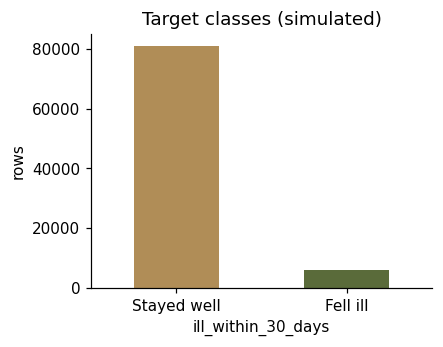

In [7]:
counts = table[LABEL].value_counts().rename({0: "Stayed well", 1: "Fell ill"})
ax = counts.plot.bar(color=[TAN, OLIVE], rot=0, figsize=(4, 3), title="Target classes (simulated)")
ax.set_ylabel("rows");

## 5. Initial EDA

To understand the farm's herd, when illness happens and the most common illnesses.

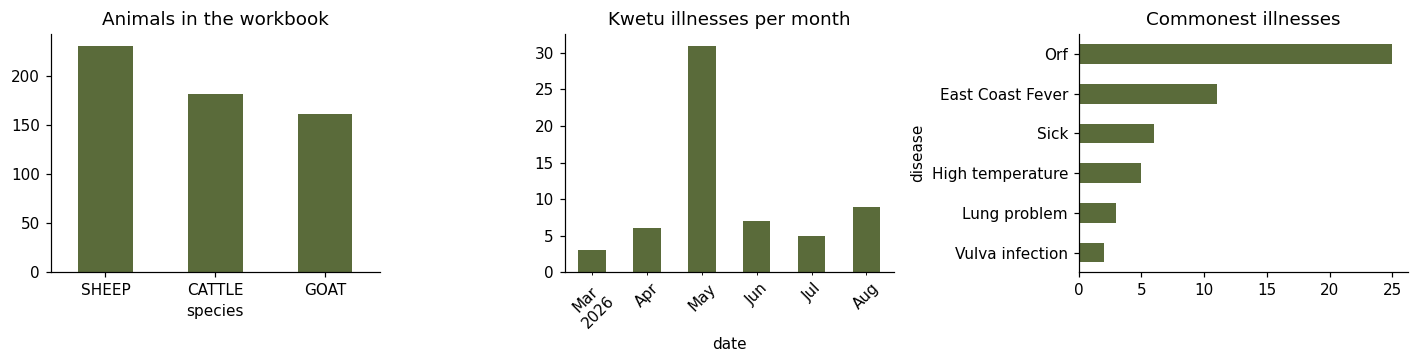

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.4))
kwetu["livestock"]["species"].value_counts().plot.bar(ax=axes[0], color=OLIVE, rot=0, title="Animals in the workbook")

ill_real = kwetu["health"][kwetu["health"]["record_type"] == "ILLNESS"]
ill_real.groupby(ill_real["date"].dt.to_period("M")).size().plot.bar(ax=axes[1], color=OLIVE, rot=45,
                                                                    title="Kwetu illnesses per month")
top = ill_real["disease"].str.split(" \\(").str[0].value_counts().head(6)
top.sort_values().plot.barh(ax=axes[2], color=OLIVE, title="Commonest illnesses")
plt.tight_layout()

Then the training table: column types, missing values, and the spread of each clue.

In [9]:
print(table[FEATURES].dtypes.to_string(), "\n")
print("Missing values per column:")
print(table[["species"] + FEATURES + [LABEL]].isna().sum().to_string())
table[FEATURES].describe().round(1)

age_days                    int64
days_since_deworming      float64
days_since_vaccination    float64
illnesses_last_year         int64
rainy_season                int64 

Missing values per column:
species                   0
age_days                  0
days_since_deworming      0
days_since_vaccination    0
illnesses_last_year       0
rainy_season              0
ill_within_30_days        0


,age_days,days_since_deworming,days_since_vaccination,illnesses_last_year,rainy_season
count,86887.0,86887.0,86887.0,86887.0,86887.0
mean,1430.2,66.0,81.6,0.7,0.5
std,1123.6,78.5,72.5,1.0,0.5
min,0.0,0.0,0.0,0.0,0.0
25%,417.0,25.0,27.0,0.0,0.0
50%,1181.0,50.0,64.0,0.0,0.0
75%,2325.0,76.0,119.0,1.0,1.0
max,4693.0,365.0,365.0,8.0,1.0


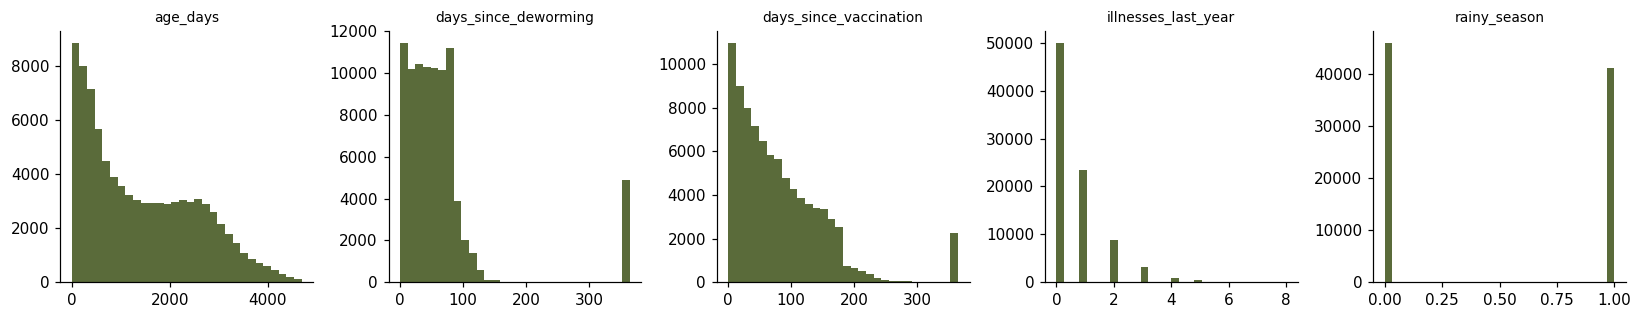

In [10]:
fig, axes = plt.subplots(1, len(FEATURES), figsize=(15, 3))
for ax, column in zip(axes, FEATURES):
    ax.hist(table[column], bins=30, color=OLIVE)
    ax.set_title(column, fontsize=9)
plt.tight_layout()

This shows`days_since_deworming` and `days_since_vaccination` pile up at 365 (never, or more than a year ago, both count as 365). `illnesses_last_year` is mostly 0 with a long tail as most animals are rarely ill and a few are ill often. There are no missing values in the simulated data.

## 6. Measures of relationship

This is to show the relationship between one feature and falling ill, along with the relationship with each other.

I am using **Spearman correlation**, **Mutual information** and **Illness rate per group**.


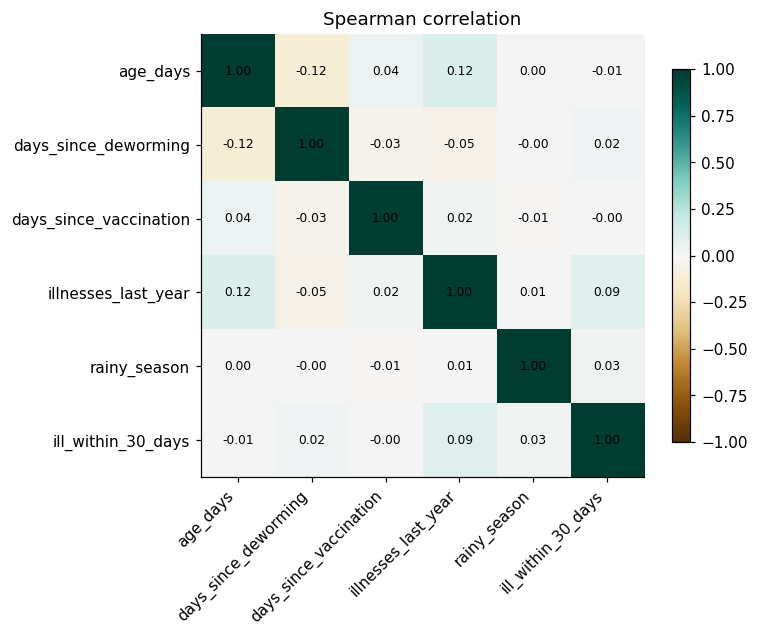

In [11]:
corr = table[FEATURES + [LABEL]].corr(method="spearman")
fig, ax = plt.subplots(figsize=(6.5, 5.5))
im = ax.imshow(corr, cmap="BrBG", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=45, ha="right")
ax.set_yticks(range(len(corr)), corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
fig.colorbar(im, ax=ax, shrink=0.8)
ax.set_title("Spearman correlation");

In [12]:
mi = mutual_info_classif(table[FEATURES], table[LABEL], random_state=SEED)
pd.DataFrame({"spearman_with_target": corr[LABEL].drop(LABEL), "mutual_information": mi},
             index=FEATURES).sort_values("mutual_information", ascending=False).round(4)

,spearman_with_target,mutual_information
rainy_season,0.0268,0.0119
illnesses_last_year,0.0939,0.0078
days_since_deworming,0.0160,0.0005
age_days,-0.0050,0.0002
days_since_vaccination,-0.0020,0.0000


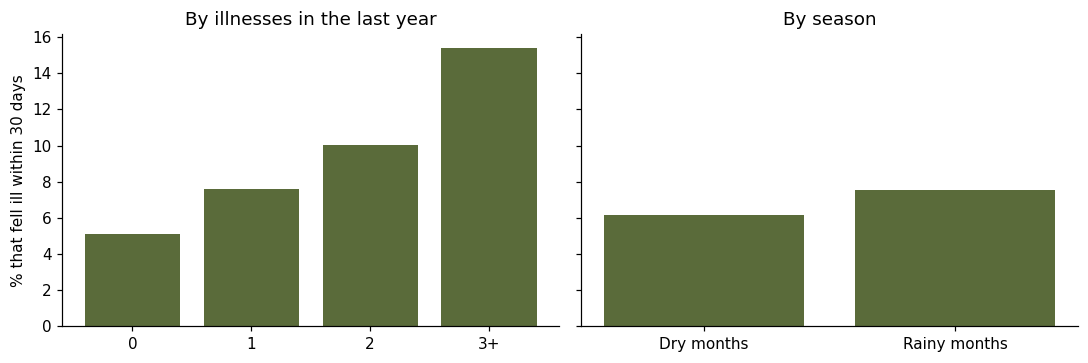

In [13]:
fig, (left, right) = plt.subplots(1, 2, figsize=(10, 3.4), sharey=True)
by_history = table.groupby(table["illnesses_last_year"].clip(upper=3))[LABEL].mean() * 100
left.bar(["0", "1", "2", "3+"], by_history.values, color=OLIVE)
left.set_title("By illnesses in the last year")
left.set_ylabel("% that fell ill within 30 days")
by_season = table.groupby("rainy_season")[LABEL].mean() * 100
right.bar(["Dry months", "Rainy months"], by_season.values, color=OLIVE)
right.set_title("By season")
plt.tight_layout()

Past illness has the strongest correlation with falling ill, and the season carries the most mutual information then deworming comes next. The relationships are real but weak as on a farm, most illness is down to chance that records can't foresee. The clues aren't strongly correlated with each other either, so none is a copy of another.

## 7. Train/Test Split

I decided to split the data by time, training the model on the older 75% of days and testing on the newer 25%. This is so that it does not get a glimpse into the future that it is trying to predict.

In [14]:
learn, test = split_by_time(table)
print(f"Learn: {len(learn):,} rows, {learn['snapshot'].min():%d %b %Y} to {learn['snapshot'].max():%d %b %Y}, {learn[LABEL].mean():.1%} ill")
print(f"Test:  {len(test):,} rows, {test['snapshot'].min():%d %b %Y} to {test['snapshot'].max():%d %b %Y}, {test[LABEL].mean():.1%} ill")

Learn: 61,598 rows, 30 Dec 2023 to 13 Dec 2025, 6.8% ill
Test:  25,289 rows, 27 Dec 2025 to 22 Aug 2026, 7.0% ill


## 8. Feature selection

The app uses five features in its classification. Four other candidates are compared below.

- `days_since_illness`: days since the animal's last illness
- `illnesses_last_90_days`: recent illnesses only
- `herd_cases_last_30_days`: illnesses in the same herd recently (contagion)
- `is_female`

Everything that selects features looks **only at the training rows**, so the test rows stay unseen.

In [15]:
def candidate_features(table, data):
    """Add four more possible clues. Like the others, they only use records on or before the snapshot."""
    t = table.merge(data["livestock"][["animal_id", "farm", "gender"]], on="animal_id", how="left")
    t = t.sort_values("snapshot").reset_index(drop=True)
    health = data["health"].drop(columns="farm", errors="ignore").assign(date=pd.to_datetime(data["health"]["date"]))
    ill = health[health["record_type"] == "ILLNESS"].merge(data["livestock"][["animal_id", "species", "farm"]], on="animal_id")
    t["days_since_illness"] = days_since(t, ill, "animal_id")
    last_90, herd_30 = [], []
    for day, rows in t.groupby("snapshot", sort=False):
        recent = ill[(ill["date"] > day - timedelta(days=90)) & (ill["date"] <= day)]
        last_90.append(rows["animal_id"].map(recent["animal_id"].value_counts()).fillna(0))
        month = ill[(ill["date"] > day - timedelta(days=30)) & (ill["date"] <= day)].groupby(["farm", "species"]).size()
        herd_30.append(pd.Series([month.get(key, 0) for key in zip(rows["farm"], rows["species"])], index=rows.index))
    t["illnesses_last_90_days"] = pd.concat(last_90).astype(int)
    t["herd_cases_last_30_days"] = pd.concat(herd_30).astype(int)
    t["is_female"] = (t["gender"] == "FEMALE").astype(int)
    return t.drop(columns="gender")


EXTRA = ["days_since_illness", "illnesses_last_90_days", "herd_cases_last_30_days", "is_female"]
CANDIDATES = FEATURES + EXTRA
table = candidate_features(table, data)
learn, test = split_by_time(table)

mi = mutual_info_classif(learn[CANDIDATES], learn[LABEL], random_state=SEED)
pd.Series(mi, index=CANDIDATES, name="mutual information (training rows)").sort_values(ascending=False).round(4)

days_since_illness         0.0123
is_female                  0.0123
rainy_season               0.0078
illnesses_last_year        0.0066
herd_cases_last_30_days    0.0020
illnesses_last_90_days     0.0018
days_since_vaccination     0.0001
age_days                   0.0000
days_since_deworming       0.0000
Name: mutual information (training rows), dtype: float64

## 9. RFE (recursive feature elimination)

RFE fits a model, drops the weakest feature, refits, and repeats. RFECV scores each feature count with cross-validation and keeps the best number. A **rank of 1** means the feature was kept.

Features are scaled first to make it fair.

In [16]:
X_rfe = pd.get_dummies(learn[["species"] + CANDIDATES], columns=["species"], dtype=float)
rfe = Pipeline([
    ("scale", StandardScaler()),
    ("rfe", RFECV(LogisticRegression(max_iter=1000), cv=TimeSeriesSplit(4), scoring="roc_auc", min_features_to_select=3)),
]).fit(X_rfe, learn[LABEL])

selector = rfe.named_steps["rfe"]
print("RFECV kept", selector.n_features_, "of", X_rfe.shape[1], "columns")
pd.Series(selector.ranking_, index=X_rfe.columns, name="rank (1 = kept)").sort_values()

RFECV kept 9 of 12 columns


days_since_deworming       1
illnesses_last_year        1
days_since_illness         1
rainy_season               1
illnesses_last_90_days     1
herd_cases_last_30_days    1
species_CATTLE             1
is_female                  1
species_GOAT               1
age_days                   2
species_SHEEP              3
days_since_vaccination     4
Name: rank (1 = kept), dtype: int64

RFE keeps most columns: no single one is useless. The real test is whether the extra clues improve the model so the next sections compare the five app features with all nine using cross-validation.

## 10. Data preprocessing and transformation (on the training data)

Two transformations done inside a Pipeline, so cross-validation and the test set never leak into them.

- **One-hot encoding** turns species into a numeric value.
- **Standard scaling** puts every number on the same scale (mean 0, standard deviation 1). Then a logistic regression weight means "the effect of one typical step up", which makes the weights comparable.

A **log transform** is also tried on the skewed count, to see if it helps.

In [17]:
def make_pipeline(columns, model, log_counts=False):
    numbers = Pipeline([("log", FunctionTransformer(np.log1p)), ("scale", StandardScaler())]) if log_counts else StandardScaler()
    prepare = ColumnTransformer([
        ("species", OneHotEncoder(handle_unknown="ignore"), ["species"]),
        ("numbers", numbers, columns),
    ])
    return Pipeline([("prepare", prepare), ("model", model)])


demo = make_pipeline(FEATURES, LogisticRegression(max_iter=1000)).fit(learn[["species"] + FEATURES], learn[LABEL])
prepared = demo.named_steps["prepare"].transform(learn[["species"] + FEATURES].head())
pd.DataFrame(prepared, columns=demo.named_steps["prepare"].get_feature_names_out()).round(2)

,species__species_CATTLE,species__species_GOAT,species__species_SHEEP,numbers__age_days,numbers__days_since_deworming,numbers__days_since_vaccination,numbers__illnesses_last_year,numbers__rainy_season
0,1.0,0.0,0.0,-0.62,0.02,3.72,-0.66,-1.02
1,1.0,0.0,0.0,1.34,0.02,-0.39,-0.66,-1.02
2,1.0,0.0,0.0,0.67,0.02,3.72,-0.66,-1.02
3,1.0,0.0,0.0,0.63,0.02,-0.42,-0.66,-1.02
4,1.0,0.0,0.0,1.48,0.02,3.72,-0.66,-1.02


## 11. Class imbalance and resampling

With 7% positives, a model can look good by mostly saying "no". Three ways of handling it are compared on the test rows:
- **None:** train as is.
- **Class weights:** tell the model that each sick row counts about 13 times as much (`class_weight="balanced"`).
- **Random oversampling:** copy sick rows (in the training data only, never the test data) until there are as many as healthy rows.

What matters is the ranking (ROC AUC), and whether the predicted chances stay realistic, because the app shows them to the farmer as percentages.

In [18]:
cols = ["species"] + FEATURES
sick, well = learn[learn[LABEL] == 1], learn[learn[LABEL] == 0]
oversampled = pd.concat([well, sick.sample(len(well), replace=True, random_state=SEED)])

rows = []
for name, model, train_rows in [
    ("None", LogisticRegression(max_iter=1000), learn),
    ("Class weights", LogisticRegression(max_iter=1000, class_weight="balanced"), learn),
    ("Random oversampling", LogisticRegression(max_iter=1000), oversampled),
]:
    fitted = make_pipeline(FEATURES, model).fit(train_rows[cols], train_rows[LABEL])
    p = fitted.predict_proba(test[cols])[:, 1]
    rows.append({"method": name, "training rows": len(train_rows), "ROC AUC": roc_auc_score(test[LABEL], p),
                 "recall at 0.5": ((p >= 0.5) & (test[LABEL] == 1)).sum() / test[LABEL].sum(),
                 "average predicted chance": p.mean(), "real share ill": test[LABEL].mean()})
pd.DataFrame(rows).set_index("method").round(3)

,training rows,ROC AUC,recall at 0.5,average predicted chance,real share ill
method,,,,,
None,61598,0.599,0.000,0.070,0.07
Class weights,61598,0.598,0.518,0.486,0.07
Random oversampling,114866,0.599,0.527,0.487,0.07


## 12. Cross-validation and the ML pipeline

l**Cross-validation** tests the pipeline on several slices of the training data, giving an average and a spread instead of one lucky or unlucky number. 

TimeSeriesSplit keeps time order with each fold trains on earlier rows and validates on the next ones.

In [19]:
cv = TimeSeriesSplit(n_splits=5)
for name, columns, log_counts in [("5 app features", FEATURES, False),
                                  ("5 app features, log counts", FEATURES, True),
                                  ("all 9 candidates", CANDIDATES, False)]:
    scores = cross_validate(make_pipeline(columns, LogisticRegression(max_iter=1000), log_counts),
                            learn[["species"] + columns], learn[LABEL], cv=cv,
                            scoring=["roc_auc", "average_precision"])
    print(f"{name:28} ROC AUC {scores['test_roc_auc'].mean():.3f} ± {scores['test_roc_auc'].std():.3f}   "
          f"average precision {scores['test_average_precision'].mean():.3f}")

5 app features               ROC AUC 0.626 ± 0.021   average precision 0.117
5 app features, log counts   ROC AUC 0.620 ± 0.019   average precision 0.115
all 9 candidates             ROC AUC 0.623 ± 0.020   average precision 0.116


This makes me choose just the 5 features. The four extra features and log transform don't do much to help. ROC AUC doiesn't improve.

## 13. Diagnostic EDA

The chosen pipeline is trained on all training rows and checked on the test rows. How it behaves is analysed. Questions such as the ones below are asked and answered. 

- Do sick animals get higher predicted chances than healthy ones?
- When it says 10%, do about 10% really fall ill?
- Does it do worse for any species or season?

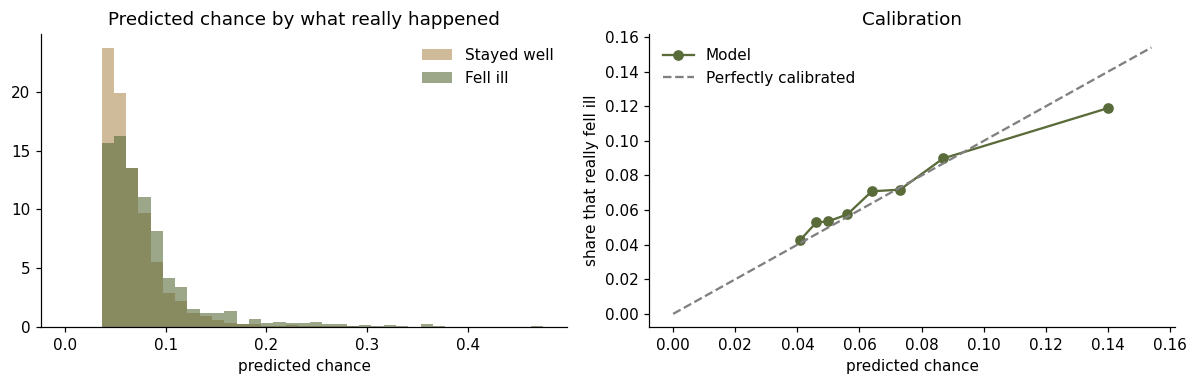

In [21]:
model = make_pipeline(FEATURES, LogisticRegression(max_iter=1000)).fit(learn[cols], learn[LABEL])
chance = model.predict_proba(test[cols])[:, 1]
test = test.assign(chance=chance)

fig, (left, right) = plt.subplots(1, 2, figsize=(11, 3.6))
bins = np.linspace(0, chance.max(), 40)
left.hist(chance[test[LABEL] == 0], bins=bins, density=True, alpha=0.6, color=TAN, label="Stayed well")
left.hist(chance[test[LABEL] == 1], bins=bins, density=True, alpha=0.6, color=OLIVE, label="Fell ill")
left.set_xlabel("predicted chance")
left.set_title("Predicted chance by what really happened")
left.legend(frameon=False)

real_share, predicted = calibration_curve(test[LABEL], chance, n_bins=8, strategy="quantile")
right.plot(predicted, real_share, "o-", color=OLIVE, label="Model")
lim = max(predicted.max(), real_share.max()) * 1.1
right.plot([0, lim], [0, lim], "--", color="grey", label="Perfectly calibrated")
right.set_xlabel("predicted chance")
right.set_ylabel("share that really fell ill")
right.set_title("Calibration")
right.legend(frameon=False)
plt.tight_layout()

## 14. Confusion matrix

The app's "High" level starts at 10%, so that threshold is used. True Positive, False Positive, False Negative and True Negatives are compared.

- **True positive:** flagged, and it did fall ill (caught early)
- **False positive:** flagged, but it stayed well (a check that wasn't needed)
- **False negative:** not flagged, but it fell ill (missed)
- **True negative:** not flagged, stayed well

Precision: 12.3% of flagged animals fell ill (base rate 7.0%)
Recall:    19.7% of the animals that fell ill were flagged
Flagged:   11.2% of all animal-checks


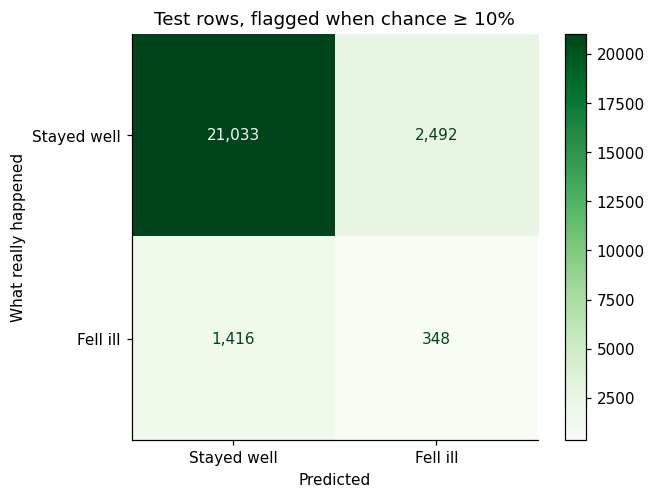

In [22]:
flagged = (chance >= HIGH_FROM).astype(int)
matrix = confusion_matrix(test[LABEL], flagged)
ConfusionMatrixDisplay(matrix, display_labels=["Stayed well", "Fell ill"]).plot(cmap="Greens", values_format=",")
plt.title(f"Test rows, flagged when chance ≥ {HIGH_FROM:.0%}")
plt.xlabel("Predicted")
plt.ylabel("What really happened")

tn, fp, fn, tp = matrix.ravel()
print(f"Precision: {tp / (tp + fp):.1%} of flagged animals fell ill (base rate {test[LABEL].mean():.1%})")
print(f"Recall:    {tp / (tp + fn):.1%} of the animals that fell ill were flagged")
print(f"Flagged:   {(tp + fp) / len(test):.1%} of all animal-checks")

The chosen threshold is a trade-off. This is because a lower one catches more sick animals but flags more healthy ones. The table shows several choices, including the app's two boundaries:

In [23]:
rows = []
for threshold in [0.04, LOW_BELOW, 0.08, HIGH_FROM, 0.12, 0.15]:
    f = chance >= threshold
    rows.append({"threshold": threshold, "share flagged": f.mean(),
                 "precision": test[LABEL][f].mean() if f.any() else np.nan,
                 "recall": f[test[LABEL] == 1].mean()})
pd.DataFrame(rows).set_index("threshold").round(3)

,share flagged,precision,recall
threshold,,,
0.04,0.953,0.071,0.973
0.06,0.492,0.088,0.624
0.08,0.233,0.106,0.353
0.10,0.112,0.123,0.197
0.12,0.063,0.139,0.126
0.15,0.032,0.187,0.086


## 15. ROC curve

The ROC curve shows every threshold at once ie. how many sick animals are caught (up) against how many healthy ones are flagged (across).  **ROC AUC** is the area under the curve, it shows the chance that a random sick animal gets a higher score than a random healthy one. 

The precision–recall curve beside it is often more telling when positives are rare.

test_rows                25289.000
share_that_fell_ill          0.070
accuracy_if_always_no        0.930
roc_auc                      0.599
precision_of_flagged         0.111
recall_of_flagged            0.317
dtype: float64

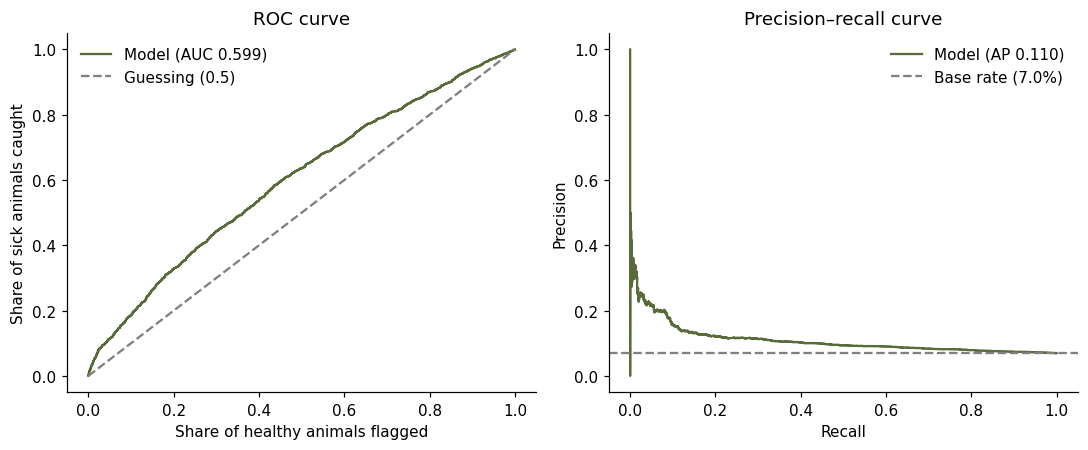

In [24]:
fpr, tpr, _ = roc_curve(test[LABEL], chance)
precision, recall, _ = precision_recall_curve(test[LABEL], chance)
auc, ap = roc_auc_score(test[LABEL], chance), average_precision_score(test[LABEL], chance)

fig, (left, right) = plt.subplots(1, 2, figsize=(10, 4.2))
left.plot(fpr, tpr, color=OLIVE, label=f"Model (AUC {auc:.3f})")
left.plot([0, 1], [0, 1], "--", color="grey", label="Guessing (0.5)")
left.set_xlabel("Share of healthy animals flagged")
left.set_ylabel("Share of sick animals caught")
left.set_title("ROC curve")
left.legend(frameon=False)
right.plot(recall, precision, color=OLIVE, label=f"Model (AP {ap:.3f})")
right.axhline(test[LABEL].mean(), linestyle="--", color="grey", label=f"Base rate ({test[LABEL].mean():.1%})")
right.set_xlabel("Recall")
right.set_ylabel("Precision")
right.set_title("Precision–recall curve")
right.legend(frameon=False)
plt.tight_layout()

pd.Series(measure(test[LABEL].to_numpy(), chance))

## 16. Evaluating multiple models

Four other model types are compared with the same features, the same pipeline and the same time-based cross-validation to see if logistic regression was the best choice.

- a decision tree
- a random forest 
- gradient boosting 
- naive Bayes

The trees are kept shallow, with large leaves, so they don't memorise the training rows.

In [25]:
candidates = {
    "Logistic regression": LogisticRegression(max_iter=1000),
    "Decision tree": DecisionTreeClassifier(max_depth=5, min_samples_leaf=100, random_state=SEED),
    "Random forest": RandomForestClassifier(n_estimators=200, max_depth=8, min_samples_leaf=50, n_jobs=-1, random_state=SEED),
    "Gradient boosting": HistGradientBoostingClassifier(random_state=SEED),
    "Naive Bayes": GaussianNB(),
}
rows = []
for name, estimator in candidates.items():
    began = time.time()
    scores = cross_validate(make_pipeline(FEATURES, estimator), learn[cols], learn[LABEL], cv=cv, scoring="roc_auc")
    rows.append({"model": name, "CV ROC AUC": scores["test_score"].mean(), "spread": scores["test_score"].std(),
                 "seconds": time.time() - began})
results = pd.DataFrame(rows).set_index("model").sort_values("CV ROC AUC", ascending=False)
results.round(3)

,CV ROC AUC,spread,seconds
model,,,
Logistic regression,0.626,0.021,0.919
Naive Bayes,0.622,0.025,0.201
Random forest,0.611,0.015,6.820
Decision tree,0.594,0.026,0.657
Gradient boosting,0.592,0.015,1.230


Logistic regression still remains the choice of model.

It scores as well as or better than the more complex models, trains in a fraction of a second, gives calibrated chances, and every weight can be explained. More complex models would only be worth it if they were clearly more accurate, and here they aren't.

## 17. Hyperparameter tuning

Hyperparameters are settings chosen before training. For logistic regression the main one is **C**, which controls regularisation: a small C keeps weights small (simpler, guards against over-fitting), a large C lets the data decide. `GridSearchCV` tries each value with the same time-based cross-validation and keeps the best. Gradient boosting gets a small grid too, to give the strongest alternative a fair chance.

In [26]:
search = GridSearchCV(make_pipeline(FEATURES, LogisticRegression(max_iter=1000)),
                      {"model__C": [0.01, 0.1, 1, 10]}, cv=cv, scoring="roc_auc")
search.fit(learn[cols], learn[LABEL])
print("Logistic regression, best:", search.best_params_, f"CV ROC AUC {search.best_score_:.3f}")
display(pd.DataFrame(search.cv_results_)[["param_model__C", "mean_test_score", "std_test_score"]].round(4))

boost = GridSearchCV(make_pipeline(FEATURES, HistGradientBoostingClassifier(random_state=SEED)),
                     {"model__learning_rate": [0.03, 0.1], "model__max_depth": [3, None], "model__max_iter": [100, 300]},
                     cv=cv, scoring="roc_auc")
boost.fit(learn[cols], learn[LABEL])
print("Gradient boosting, best:", boost.best_params_, f"CV ROC AUC {boost.best_score_:.3f}")

Logistic regression, best: {'model__C': 10} CV ROC AUC 0.626


,param_model__C,mean_test_score,std_test_score
0,0.01,0.6256,0.0203
1,0.10,0.6256,0.0208
2,1.00,0.6256,0.0207
3,10.00,0.6256,0.0207


Gradient boosting, best: {'model__learning_rate': 0.03, 'model__max_depth': 3, 'model__max_iter': 100} CV ROC AUC 0.614


C barely matters. With tens of thousands of rows and only eight weights, the model isn't at risk of over-fitting. Tuned gradient boosting improves but still doesn't beat logistic regression. The tuned logistic regression is the final model.

In [27]:
final = search.best_estimator_                 # already refitted on all training rows by GridSearchCV
chance = final.predict_proba(test[cols])[:, 1]
test = test.assign(chance=chance)
print(f"Final model on the test rows: ROC AUC {roc_auc_score(test[LABEL], chance):.3f}")

Final model on the test rows: ROC AUC 0.599


## 18. Explainability

Logistic regression adds up one weight per clue, and the total becomes a probability. exp(weight) is an odds ratio. 

How much one typical step up in that clue (one standard deviation, because of the scaling) multiplies the odds of falling ill. 

1.00 means no effect, above 1 raises the risk, below 1 lowers it. The species ratios compare against the overall starting odds, so read them as relative to each other.

illnesses_last_year       1.43
days_since_deworming      1.14
rainy_season              1.10
age_days                  1.01
days_since_vaccination    1.01
species_GOAT              0.55
species_SHEEP             0.53
species_CATTLE            0.46
Name: odds ratio, dtype: float64

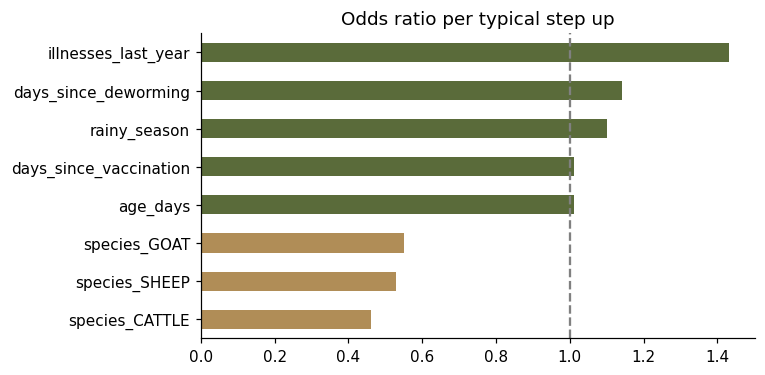

In [28]:
odds = pd.Series(weights(final), name="odds ratio").sort_values()
colours = [OLIVE if v >= 1 else TAN for v in odds]
ax = odds.plot.barh(color=colours, figsize=(6.5, 3.6), title="Odds ratio per typical step up")
ax.axvline(1, color="grey", linestyle="--")
odds.sort_values(ascending=False).round(2)

### Permutation importance

Under this, I remove one feature on the test rows and see how much ROC AUC drops. A big drop means the model relies on it. 

In [29]:
importance = permutation_importance(final, test[cols], test[LABEL], scoring="roc_auc",
                                    n_repeats=5, random_state=SEED)
pd.Series(importance.importances_mean, index=cols, name="drop in ROC AUC when shuffled").sort_values(ascending=False).round(4)

illnesses_last_year       0.0852
days_since_deworming      0.0085
rainy_season              0.0059
species                   0.0023
days_since_vaccination    0.0000
age_days                 -0.0002
Name: drop in ROC AUC when shuffled, dtype: float64

### Explaining one animal

For any single animal, each clue's contribution is its weight × its scaled value. 

In [30]:
animal = test.sort_values("chance", ascending=False).iloc[[0]]
prepare, logreg = final.named_steps["prepare"], final.named_steps["model"]
contributions = pd.Series(prepare.transform(animal[cols])[0] * logreg.coef_[0],
                          index=[n.split("__")[1] for n in prepare.get_feature_names_out()])
print(f"Riskiest test animal: {animal['species'].iloc[0].title()}, chance {animal['chance'].iloc[0]:.1%} ({risk_level(animal['chance'].iloc[0])})")
display(animal[FEATURES].T.rename(columns=lambda _: "value"))
contributions.sort_values(ascending=False).round(3).rename("adds to the log-odds")

Riskiest test animal: Goat, chance 47.5% (High)


,value
age_days,344.0
days_since_deworming,83.0
days_since_vaccination,162.0
illnesses_last_year,7.0
rainy_season,1.0


illnesses_last_year       2.408
rainy_season              0.096
days_since_deworming      0.026
days_since_vaccination    0.006
species_SHEEP            -0.000
species_CATTLE           -0.000
age_days                 -0.009
species_GOAT             -0.605
Name: adds to the log-odds, dtype: float64

## 19. Testing on Kwetu's real records

The final check of how the model, trained on simulated farms, does on a real farm's records. Kwetu records are used to test this as the data was not used for training.

In [31]:
real_chance = final.predict_proba(real[cols])[:, 1]
real = real.assign(chance=real_chance, risk=[risk_level(c) for c in real_chance])
print(f"Kwetu rows: {len(real):,}, fell ill: {real[LABEL].sum()} ({real[LABEL].mean():.1%})")
print(f"ROC AUC on real records: {roc_auc_score(real[LABEL], real_chance):.3f}")
real.groupby("risk")[LABEL].agg(rows="size", share_fell_ill="mean").reindex(["Low", "Medium", "High"]).round(3)

Kwetu rows: 3,348, fell ill: 115 (3.4%)
ROC AUC on real records: 0.652


,rows,share_fell_ill
risk,,
Low,73,0.014
Medium,3089,0.037
High,186,0.000


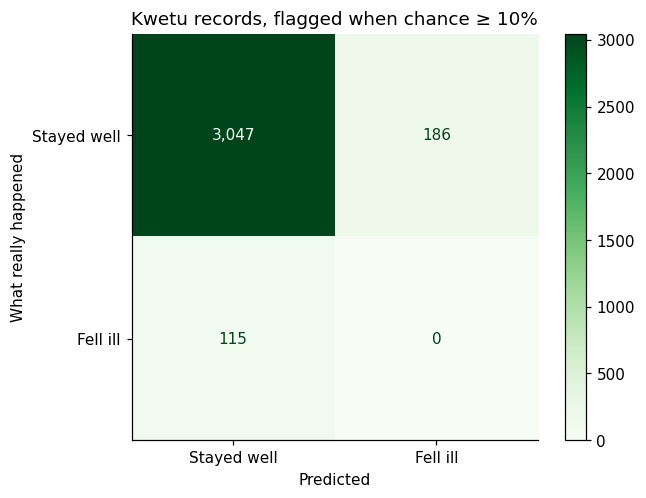

In [32]:
ConfusionMatrixDisplay(confusion_matrix(real[LABEL], (real_chance >= HIGH_FROM).astype(int)),
                       display_labels=["Stayed well", "Fell ill"]).plot(cmap="Greens", values_format=",")
plt.title(f"Kwetu records, flagged when chance ≥ {HIGH_FROM:.0%}")
plt.xlabel("Predicted")
plt.ylabel("What really happened");

In [33]:
real.groupby(real["illnesses_last_year"].clip(upper=1))[LABEL].agg(rows="size", share_fell_ill="mean") \
    .rename(index={0: "not ill in the last year", 1: "ill before"}).round(3)

,rows,share_fell_ill
illnesses_last_year,,
not ill in the last year,3075,0.036
ill before,273,0.015


### What the real records say.

The model ranks Kwetu's animals better than chance (ROC AUC about 0.65), but its "High" level didn't catch the real illnesses. The reason is visible in the EDA where most of Kwetu's illnesses were one Orf outbreak in May 2026, which spread through the herd whatever each animal's history. On these records, animals that had been ill before were less likely to fall ill again, the opposite of what the simulator assumes. The High animals were mostly ones treated earlier in the outbreak, which then recovered.

## 20. Saving the model as a pickle file

`save_bundle()` (in `ml/train.py`) pickles one dictionary which includes the fitted pipeline plus everything needed to use and explain it (the columns it expects, the target, its test results, the date, the training data, the scikit-learn version). 

The app's Illness risk page loads this file.

In [34]:
final_chance = final.predict_proba(test[cols])[:, 1]          # the final model's chances on the test rows

metrics = measure(test[LABEL].to_numpy(), final_chance)
metrics["roc_auc_kwetu_records"] = round(float(roc_auc_score(real[LABEL], final.predict_proba(real[cols])[:, 1])), 3)
metrics["best_C"] = search.best_params_["model__C"]
metrics["odds_multipliers"] = weights(final)

bundle = save_bundle(final, metrics)
print(f"Saved {MODEL_PATH.name}: {MODEL_PATH.stat().st_size / 1024:.1f} KB")
{key: value for key, value in bundle.items() if key != "model"}

Saved illness_model.pkl: 3.0 KB


{'columns': ['species',
  'age_days',
  'days_since_deworming',
  'days_since_vaccination',
  'illnesses_last_year',
  'rainy_season'],
 'label': 'ill_within_30_days',
 'horizon_days': 30,
 'metrics': {'test_rows': 25289,
  'share_that_fell_ill': 0.07,
  'accuracy_if_always_no': 0.93,
  'roc_auc': 0.599,
  'precision_of_flagged': 0.111,
  'recall_of_flagged': 0.317,
  'roc_auc_kwetu_records': 0.652,
  'best_C': 10,
  'odds_multipliers': {'species_CATTLE': 0.46,
   'species_GOAT': 0.55,
   'species_SHEEP': 0.53,
   'age_days': 1.01,
   'days_since_deworming': 1.14,
   'days_since_vaccination': 1.01,
   'illnesses_last_year': 1.43,
   'rainy_season': 1.1}},
 'trained_on': '2026-11-06',
 'training_data': 'Simulated Kwetu-like farms, 3 years to 2026-09-30',
 'sklearn_version': '1.9.1'}

In [35]:
loaded = load_bundle()
again = loaded["model"].predict_proba(test[loaded["columns"]])[:, 1]
print("Same predictions after loading:", bool(np.allclose(again, test["chance"])))

Same predictions after loading: True
